# Homework 7 — Recurrent Neural Networks and LSTMs (PyTorch)
**CSCI1409 Deep Learning | Aidyn Abirov | Week 7**

Fill in every `# TODO`. Do **not** change the `assert` lines: they tell you when a cell is correct. Write your explanations in the **Your answer** cells.

- **Tasks 1–2: no AI.** Task 3: AI allowed for explanations and debugging only (record which tool and what for).
- Save as `Surname_Firstname_Homework07.ipynb`, restart the kernel, **Run All**, and submit via Teams.
- Task 3 downloads a list of 32,000 names (about 230 KB) the first time. A GPU is not needed: all training takes well under a minute on a laptop CPU.

In [2]:
import os, math, time, random, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_printoptions(precision=4, sci_mode=False)

## Task 1 — An RNN step by step (no AI, about 30 minutes)

A simple RNN reads a sequence one element at a time and keeps a **hidden state** $h_t$, its memory of everything it has read so far:

$$h_t = \tanh\left(W_{xh}\, x_t + W_{hh}\, h_{t-1} + b\right), \qquad h_0 = 0$$

The **same** weights are used at every time step.

**1a. By hand.** Use a tiny RNN with one input and one hidden unit: $h_t = \tanh(1 \cdot x_t + 0.5 \cdot h_{t-1})$, with $h_0 = 0$. Compute $h_1, h_2, h_3$ (4 decimals) for two sequences that contain the same numbers in a different order:

- sequence A: $x = (1, 0, 0)$
- sequence B: $x = (0, 0, 1)$

Type your results below. They are checked in 1b.

In [3]:
# TODO: your hand results h1, h2, h3
hand_A = torch.tensor([0.7616, 0.3634, 0.1791])
hand_B = torch.tensor([0.0, 0.0, 0.7616])

**1b. From scratch.** Complete `rnn_forward`. It receives one sequence `x` of shape `(seq_len, input_size)` and returns all hidden states, shape `(seq_len, hidden_size)`. Use one loop over time; do not call `nn.RNN` inside it.

With vectors, the update is `h = tanh(x_t @ W_xh.T + h @ W_hh.T + b)`.

In [4]:
def rnn_forward(x, W_xh, W_hh, b, h0):
    h = h0
    states = []
    for t in range(x.shape[0]):
        # TODO: update h using x[t], the previous h, and the weights (see the formula above)
        h = torch.tanh(x[t] @ W_xh.T + h @ W_hh.T + b)
        states.append(h)
    return torch.stack(states)

# Check 1: your hand calculation (1 input, 1 hidden unit)
assert hand_A.abs().sum() > 0 and hand_B.abs().sum() > 0, "fill in your hand results in 1a first"
W_xh, W_hh, b, h0 = torch.tensor([[1.0]]), torch.tensor([[0.5]]), torch.zeros(1), torch.zeros(1)
for seq, hand in [([1., 0., 0.], hand_A), ([0., 0., 1.], hand_B)]:
    states = rnn_forward(torch.tensor(seq).view(3, 1), W_xh, W_hh, b, h0).flatten()
    print(seq, "->", states)
    assert torch.allclose(states, hand, atol=1e-3), "your function differs from your hand calculation"

# Check 2: PyTorch's nn.RNN with the same weights (it has two biases; we add them)
rnn = nn.RNN(input_size=3, hidden_size=4, batch_first=True)
x = torch.randn(6, 3)                                      # one sequence: 6 time steps, 3 features each
mine = rnn_forward(x, rnn.weight_ih_l0, rnn.weight_hh_l0, rnn.bias_ih_l0 + rnn.bias_hh_l0, torch.zeros(4))
torch_out, _ = rnn(x[None])                                # nn.RNN wants a batch: shape (1, 6, 3)
assert torch.allclose(mine, torch_out[0], atol=1e-5), "your function differs from nn.RNN"
print("rnn_forward matches nn.RNN")

[1.0, 0.0, 0.0] -> tensor([0.7616, 0.3634, 0.1797])
[0.0, 0.0, 1.0] -> tensor([0.0000, 0.0000, 0.7616])
rnn_forward matches nn.RNN


**1c. Shapes and parameters.** In Task 3 you will use `nn.RNN(input_size=27, hidden_size=128, batch_first=True)` on batches of 64 sequences, each 20 steps long. With `batch_first=True` the input has shape **(batch, seq_len, features)**. `nn.RNN` returns two things: `output` (the hidden state at **every** step) and `h_n` (the hidden state after the **last** step).

Fill in by hand first:
- the shapes of `output` and `h_n`;
- the number of parameters of the RNN: $W_{xh}$ is $128 \times 27$, $W_{hh}$ is $128 \times 128$, plus two bias vectors of length 128;
- the number of parameters of `nn.LSTM` with the same sizes. An LSTM has **four** sets of these weights: one for each of its gates $i, f, o$ and one for the candidate $g$.

In [5]:
# TODO: fill in by hand
output_shape = (64, 20, 128) # batch, steps, hidden_size
h_n_shape = (1, 64, 128)      # layer, batch, hidden_size)   PyTorch adds a first dimension for the number of layers (here 1)
rnn_params_by_hand = 20096
lstm_params_by_hand = 80384

rnn = nn.RNN(input_size=27, hidden_size=128, batch_first=True)
lstm = nn.LSTM(input_size=27, hidden_size=128, batch_first=True)
x = torch.randn(64, 20, 27)
output, h_n = rnn(x)
print("output:", tuple(output.shape), " h_n:", tuple(h_n.shape))
assert tuple(output.shape) == output_shape and tuple(h_n.shape) == h_n_shape
assert rnn_params_by_hand == sum(p.numel() for p in rnn.parameters())
assert lstm_params_by_hand == sum(p.numel() for p in lstm.parameters())
assert torch.allclose(output[:, -1], h_n[0]), "the last step of output is exactly h_n"
print(f"RNN: {rnn_params_by_hand:,} parameters, LSTM: {lstm_params_by_hand:,} parameters")

output: (64, 20, 128)  h_n: (1, 64, 128)
RNN: 20,096 parameters, LSTM: 80,384 parameters


**Questions 1.**
1. Sequences A and B contain the same numbers, but their final hidden states $h_3$ are very different. Why? What does this tell you about RNNs compared with a model that only sees the *sum* of the inputs?

The RNN reads the inputs in order, and each step multiplies the old memory by 0.5. In A, the “1” came first, so it was halved twice and is now weak: $h_3 = 0.1797$. In B, the “1” came last, so it is fresh: $h_3 = 0.7616$.

A model that only sees the sum gets $1 + 0 + 0 = 1$ for A and $0 + 0 + 1 = 1$ for B, so it would give the same answer for both. It cannot tell the order. An RNN can tell the order, so it can tell “dog bites man” from “man bites dog”.

2. In sequence A, the "1" was read at step 1 and then $h$ shrinks: $0.76 \to 0.36 \to 0.18$. Which weight controls how fast the memory fades? What would happen with $W_{hh} = 0$?

$W_{hh}$ controls it, because it decides how much of the old memory $h_{t-1}$ goes into the next step. With $W_{hh} = 0.5$, about half survives each step.

With $W_{hh} = 0$, the formula becomes $h_t = \tanh(x_t)$, so the old memory is ignored completely and the RNN has no memory:

A: $h = (0.7616,\ 0,\ 0)$, so the “1” is forgotten after one step
B: $h = (0,\ 0,\ 0.7616)$

The final state only shows the last input. With $W_{hh}$ closer to 1, the memory would fade more slowly.a

3. The RNN in 1c can read sequences of length 20, 200, or 2000. Does its number of parameters change? Why not?

No. It stays 20 096 for length 20, 200, or 2000.

The reason is that the same weights ($W_{xh}$, $W_{hh}$, $b$) are reused at every step. A longer sequence just means more loop iterations with the same weights. The parameter count depends only on input_size (27) and hidden_size (128), not on the number of steps.

**Your answer:**

## Task 2 — Why do we need LSTMs? (no AI, about 30 minutes)

**2a. Fading memory by hand.** Take an even simpler RNN without tanh: $h_t = w \cdot h_{t-1} + x_t$. The first input $x_1$ reaches $h_T$ multiplied by $w$ once per step, so its influence on $h_T$ (and the gradient $\partial h_T / \partial x_1$) is $w^{T-1}$. Compute this number for the six cases in the table (3 significant digits; a calculator is fine).

| $w$ | $T = 10$ | $T = 50$ |
|---|---|---|
| 0.5 | | |
| 0.9 | | |
| 1.1 | | |

In [9]:
# TODO: your hand results, rows = w (0.5, 0.9, 1.1), columns = T (10, 50)
hand_influence = torch.tensor([[0.00195, 1.78e-15],
                               [0.387, 0.00573],
                               [2.36, 107]], dtype=torch.float64)

exact = torch.tensor([[w ** (T - 1) for T in (10, 50)] for w in (0.5, 0.9, 1.1)], dtype=torch.float64)
print(exact)
assert torch.allclose(hand_influence, exact, rtol=0.02)

tensor([[  0.0020,   0.0000],
        [  0.3874,   0.0057],
        [  2.3579, 106.7190]], dtype=torch.float64)


**2b. The LSTM memory cell by hand.** An LSTM keeps a second memory, the **cell state** $c_t$, and three gates with values between 0 and 1: the forget gate $f$, the input gate $i$, and the output gate $o$. The candidate $g$ (between −1 and 1) is the new information it could write:

$$c_t = f \cdot c_{t-1} + i \cdot g, \qquad h_t = o \cdot \tanh(c_t)$$

The previous cell state is $c_{t-1} = 2$. Compute $c_t$ and $h_t$ (4 decimals) for the four cases below, then complete `lstm_update`.

| case | $f$ | $i$ | $g$ | $o$ | $c_t$ | $h_t$ |
|---|---|---|---|---|---|---|
| keep | 1 | 0 | 0.5 | 1 | | |
| overwrite | 0 | 1 | 0.5 | 1 | | |
| hide | 1 | 0 | 0.5 | 0 | | |
| mix | 0.5 | 0.5 | −1 | 0.8 | | |

In [14]:
# TODO: your hand results as (c_t, h_t) for keep, overwrite, hide, mix
hand_cell = torch.tensor([[2.0, 0.9640],
                          [0.5, 0.4621],
                          [2.0, 0.0],
                          [0.5, 0.3697]])

def lstm_update(c_prev, f, i, g, o):
    c = f * c_prev + i * g   # TODO
    h = o * torch.tanh(c)   # TODO
    return c, h

assert hand_cell.abs().sum() > 0, "fill in your hand results first"
cases = [(1, 0, 0.5, 1), (0, 1, 0.5, 1), (1, 0, 0.5, 0), (0.5, 0.5, -1, 0.8)]
mine = torch.tensor([lstm_update(torch.tensor(2.0), *map(torch.tensor, case)) for case in cases])
print(mine)
assert torch.allclose(mine, hand_cell, atol=1e-3)

tensor([[2.0000, 0.9640],
        [0.5000, 0.4621],
        [2.0000, 0.0000],
        [0.5000, 0.3697]])


**2c. A full LSTM step from scratch.** In a real LSTM the gates are not given: they are computed from $x_t$ and $h_{t-1}$, like an RNN layer, but four times. PyTorch computes all four at once and stacks them in the order **i, f, g, o**:

$$\text{z} = x_t W_{ih}^\top + h_{t-1} W_{hh}^\top + b, \qquad i = \sigma(z_i),\; f = \sigma(z_f),\; g = \tanh(z_g),\; o = \sigma(z_o)$$

Complete `lstm_step` using your `lstm_update` and compare with PyTorch's `nn.LSTMCell`.

In [18]:
def lstm_step(x, h_prev, c_prev, W_ih, W_hh, b):
    z = x @ W_ih.T + h_prev @ W_hh.T + b          # shape (4 * hidden,)
    z_i, z_f, z_g, z_o = z.chunk(4)               # split into four equal parts, in PyTorch's order
    # TODO: compute the gates i, f, o (sigmoid) and the candidate g (tanh)
    i = torch.sigmoid(z_i)
    f = torch.sigmoid(z_f)
    o = torch.sigmoid(z_o)
    g = torch.tanh(z_g)
    # TODO: use lstm_update to get the new c and h
    c, h = lstm_update(c_prev, f, i, g, o) 
    return h, c

cell = nn.LSTMCell(input_size=3, hidden_size=5)
x, h_prev, c_prev = torch.randn(3), torch.randn(5), torch.randn(5)
h_mine, c_mine = lstm_step(x, h_prev, c_prev, cell.weight_ih, cell.weight_hh, cell.bias_ih + cell.bias_hh)
h_torch, c_torch = cell(x[None], (h_prev[None], c_prev[None]))
assert torch.allclose(h_mine, h_torch[0], atol=1e-5) and torch.allclose(c_mine, c_torch[0], atol=1e-5)
print("lstm_step matches nn.LSTMCell")

lstm_step matches nn.LSTMCell


**2d. Measure the fading in real networks.** How much does the **first** input still affect the **last** hidden state? We measure the gradient $|\partial h_T / \partial x_1|$ with autograd for sequences of different lengths, for three untrained networks:
- a simple RNN;
- an LSTM with PyTorch's default starting weights (forget gate starts near $\sigma(0) = 0.5$);
- an LSTM whose forget gate starts **open**: its bias is set to 2, so $f \approx \sigma(2) = 0.88$. This is a common trick in practice.

Complete the two TODOs.

RNN                  T=5: 1.4e-02  T=10: 1.3e-03  T=20: 8.3e-07  T=50: 1.6e-14  T=100: 5.8e-28
LSTM (default)       T=5: 3.8e-03  T=10: 7.8e-05  T=20: 9.0e-07  T=50: 3.1e-14  T=100: 9.1e-27
LSTM, forget bias 2  T=5: 5.9e-02  T=10: 1.9e-02  T=20: 1.4e-02  T=50: 3.0e-03  T=100: 6.6e-04


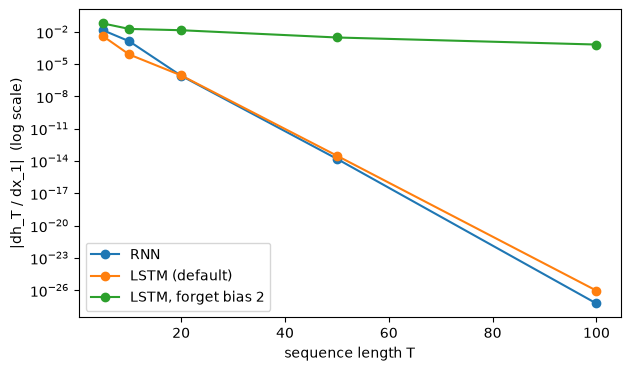

In [19]:
H = 16

def make_net(kind):
    if kind == "RNN":
        return nn.RNN(1, H, batch_first=True)
    net = nn.LSTM(1, H, batch_first=True)
    if kind == "LSTM, forget bias 2":
        with torch.no_grad():
            net.bias_ih_l0[H:2*H] = 2.0    # TODO: set the forget-gate part of net.bias_ih_l0 to 2.0 (order i, f, g, o: which slice is f?)
    return net

def first_input_gradient(net, T):
    x = torch.randn(32, T, 1, requires_grad=True)      # 32 random sequences of length T
    output, _ = net(x)
    output[:, -1].sum().backward() # TODO: backpropagate from output[:, -1].sum() (the last hidden state)
    return x.grad[:, 0].abs().mean().item()            # average |gradient| w.r.t. the FIRST input

lengths = [5, 10, 20, 50, 100]
plt.figure(figsize=(7, 4))
for kind in ["RNN", "LSTM (default)", "LSTM, forget bias 2"]:
    grads = []
    for T in lengths:
        torch.manual_seed(0)
        grads.append(first_input_gradient(make_net(kind), T))
    print(f"{kind:20s}", "  ".join(f"T={T}: {g:.1e}" for T, g in zip(lengths, grads)))
    plt.semilogy(lengths, grads, "o-", label=kind)
plt.xlabel("sequence length T"); plt.ylabel("|dh_T / dx_1|  (log scale)"); plt.legend(); plt.show()

torch.manual_seed(0)
assert first_input_gradient(make_net("LSTM, forget bias 2"), 50) > 1e-4, "check both TODOs"
assert first_input_gradient(make_net("RNN"), 50) < 1e-8

**Questions 2.**
1. In 2a, which values of $w$ make the influence of $x_1$ **vanish**, and which make it **explode**? Why is either a problem when the network must learn something that depends on an input 50 steps ago?

Vanish: $w < 1$ (0.5 and 0.9). The influence shrinks toward 0: $0.5^{49} = 1.78 \times 10^{-15}$, $0.9^{49} = 0.00573$.
Explode: $w > 1$ (1.1). The influence grows: $1.1^{49} = 107$.

2. In 2b, which case is "remembering"? Why does $f = 1, i = 0$ keep the cell state **exactly**, while a simple RNN always changes its hidden state?

The “keep” case ($f = 1$, $i = 0$): $c_t = 1 \cdot 2 + 0 \cdot 0.5 = 2$, so the old memory stays exactly the same.

It stays exact because the update is only multiply by f, then add i·g. With $f = 1$ and $i = 0$, that is $c_t = c_{t-1}$: multiplied by 1, nothing added.

A simple RNN always computes $h_t = \tanh(W_{hh} h_{t-1} + W_{xh} x_t)$. The old state is always multiplied by a weight matrix and squashed by tanh. So it changes at every step, even when nothing new comes in (in 1a it went 0.76 → 0.36 → 0.18).

3. Describe the three curves in 2d. Use 2a and 2b to explain why the LSTM with an open forget gate keeps a much larger gradient.

RNN: the gradient drops very fast as T grows, by many orders of magnitude. At T = 50 it is below $10^{-8}$.
LSTM (default): it also drops, but more slowly than the RNN.
LSTM, forget bias 2: it drops the slowest and stays the largest. At T = 50 it is still above $10^{-4}$.
Why: from 2a, the gradient to $x_1$ is a product of one factor per step. If each factor is below 1, the product vanishes. In the RNN, that factor is $W_{hh}$ times the tanh slope, which is usually well below 1. In the LSTM, the cell-state path is $c_t = f \cdot c_{t-1} + \ldots$, so the factor per step is $f$ (as in the “keep” case in 2b). With forget bias 2, $f = \text{sigmoid}(2) \approx 0.88$, which is close to 1, so the product shrinks much more slowly. The default LSTM has $f \approx 0.5$, so it lands in between.

4. In one sentence each: what do the forget gate, the input gate, and the output gate decide?

Forget gate $f$: decides how much of the old cell memory $c_{t-1}$ to keep.
Input gate $i$: decides how much of the new candidate $g$ to write into the memory.
Output gate $o$: decides how much of the memory to show as the hidden state $h_t$.

**Your answer:**

## Task 3 — A name generator (AI allowed, about 45 minutes)
AI may be used to explain concepts or help debug this task only. Record which tool you used and for what, and be ready to explain every line.

We train a **character-level language model** on 32,000 English first names: at every step it reads one letter and predicts the **next** letter. Then it invents new names, one letter at a time. The vocabulary is 27 symbols: `.` (start/end of a name) and `a`–`z`.

**3a. Data.** All names are joined into one long text `.emma.olivia.ava. …` and cut into chunks of 20 characters. For each chunk, the target is the same text **shifted one character to the left**: the correct "next letter" at every position.

By hand first: for the text `.emma.olivia.` with chunks of length 5, the first chunk is `x = ".emma"` with targets `y = "emma."`. Write down `x` and `y` for the **second** chunk.

In [21]:
if not os.path.exists("names.txt"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/makemore/master/names.txt", "names.txt")
words = open("names.txt").read().split()
random.Random(0).shuffle(words)
print(len(words), "names, for example:", words[:8])

chars = "." + "abcdefghijklmnopqrstuvwxyz"
V = len(chars)                                   # 27
stoi = {ch: i for i, ch in enumerate(chars)}     # letter -> number
decode = lambda ids: "".join(chars[i] for i in ids)

def make_chunks(names, T):
    text = "." + ".".join(names) + "."
    ids = torch.tensor([stoi[ch] for ch in text])
    n = (len(ids) - 1) // T
    x = ids[:n * T].view(n, T)
    y = ids[1:n * T + 1].view(n, T)                                     # TODO: the same as x, but shifted one character to the left
    return x, y

# TODO: your hand answer for the second chunk
hand_x1, hand_y1 = ".oliv", "olivi"
x_small, y_small = make_chunks(["emma", "olivia"], 5)
print("first chunk: ", decode(x_small[0]), "->", decode(y_small[0]))
assert decode(x_small[1]) == hand_x1 and decode(y_small[1]) == hand_y1

T = 20
split = int(0.9 * len(words))
x_train, y_train = make_chunks(words[:split], T)
x_val, y_val = make_chunks(words[split:], T)
print("train:", tuple(x_train.shape), " val:", tuple(x_val.shape))
assert torch.equal(x_train[:, 1:], y_train[:, :-1])

32033 names, for example: ['sanii', 'rhyson', 'lida', 'gennady', 'ottis', 'kervens', 'lolita', 'guillermina']
first chunk:  .emma -> emma.
train: (10272, 20)  val: (1135, 20)


**3b. The model.** Each letter enters as a **one-hot** vector of length 27 (all zeros except a 1 at the letter's position). The RNN or LSTM reads the letters, and a linear layer turns the hidden state at **every** step into 27 scores for the next letter. Complete `forward`.

`state` is the memory carried between calls: `None` at the start, then whatever `self.rnn` returned. For `nn.RNN` it is $h$; for `nn.LSTM` it is the pair $(h, c)$ — you do not have to handle the difference, just pass it along.

In [ ]:
class CharModel(nn.Module):
    def __init__(self, cell, hidden_size=128):
        super().__init__()
        rnn_class = nn.RNN if cell == "rnn" else nn.LSTM
        self.rnn = rnn_class(input_size=V, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, V)

    def forward(self, ids, state=None):
        # ids: (batch, seq_len) letter numbers
        # TODO 1: one-hot encode ids -> (batch, seq_len, 27) floats  (hint: F.one_hot(...).float())
        
        x = F.one_hot(ids, num_classes=V).float() # one-hot encode the input ids to get a tensor of shape (batch, seq_len, 27)

        # TODO 2: run self.rnn on it, starting from state -> output, state

        output, state = self.rnn(x, state) # here output is the hidden states for all time steps, and state is the final hidden state (and cell state for LSTM)

        # TODO 3: scores for the next letter at every step: self.fc(output) -> (batch, seq_len, 27)

        logits = self.fc(output) # so logits just the output of the linear layer applied to the RNN outputs
        return logits, state

for cell, expected in [("rnn", rnn_params_by_hand), ("lstm", lstm_params_by_hand)]:
    m = CharModel(cell)
    logits, _ = m(x_train[:4])
    assert logits.shape == (4, T, V)
    assert sum(p.numel() for p in m.parameters()) == expected + 128 * V + V, "should be Task 1c + the Linear layer"
print("CharModel OK")

CharModel OK


**3c. Training.** `F.cross_entropy` expects a list of predictions of shape `(N, 27)` and a list of targets of shape `(N,)`, so we flatten the batch and time dimensions together: `(batch, seq_len, 27) -> (batch * seq_len, 27)`. Complete `sequence_loss` and the four training lines.

We use `torch.optim.Adam`, a variant of gradient descent that adapts the step size for each parameter; you may treat it as a black box.

RNN: loss before training 3.299
  epoch 1: validation loss 2.287
  epoch 2: validation loss 2.251
  epoch 3: validation loss 2.215
  epoch 4: validation loss 2.189
  epoch 5: validation loss 2.182
  3 seconds
LSTM: loss before training 3.293
  epoch 1: validation loss 2.291
  epoch 2: validation loss 2.188
  epoch 3: validation loss 2.144
  epoch 4: validation loss 2.116
  epoch 5: validation loss 2.098
  5 seconds


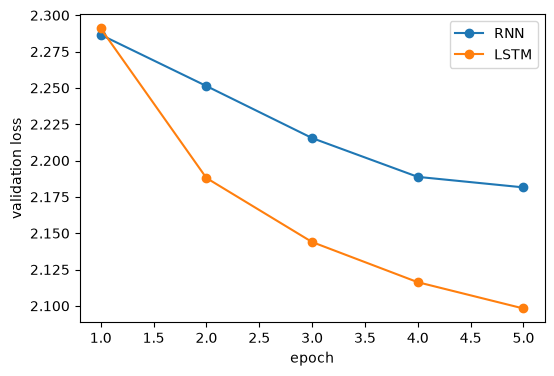

In [23]:
def sequence_loss(model, x, y):
    logits, _ = model(x)
    return F.cross_entropy(logits.reshape(-1, V), y.reshape(-1) )   # TODO: cross-entropy over all positions (reshape logits to (-1, V) and y to (-1))

def train(model, epochs=5, lr=0.005, batch_size=64):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(x_train))
        for start in range(0, len(x_train), batch_size):
            idx = perm[start:start + batch_size]
            # TODO: loss on (x_train[idx], y_train[idx]), then zero_grad, backward, step
            loss = sequence_loss(model, x_train[idx], y_train[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            history.append(sequence_loss(model, x_val, y_val).item())
        print(f"  epoch {epoch + 1}: validation loss {history[-1]:.3f}")
    return history

models, histories = {}, {}
for cell in ["rnn", "lstm"]:
    torch.manual_seed(0)
    models[cell] = CharModel(cell)
    with torch.no_grad():
        start_loss = sequence_loss(models[cell], x_val, y_val).item()
    print(f"{cell.upper()}: loss before training {start_loss:.3f}")
    assert abs(start_loss - math.log(27)) < 0.1, "an untrained model should be close to ln(27)"
    t0 = time.time(); histories[cell] = train(models[cell]); print(f"  {time.time() - t0:.0f} seconds")

plt.figure(figsize=(6, 4))
for cell, hist in histories.items():
    plt.plot(range(1, len(hist) + 1), hist, "o-", label=cell.upper())
plt.xlabel("epoch"); plt.ylabel("validation loss"); plt.legend(); plt.show()
assert histories["lstm"][-1] < 2.25, "the LSTM should reach a validation loss below 2.25; check your training loop"

**3d. Generate new names.** Start from `.`, predict the next letter, **sample** one letter from the predicted probabilities, feed it back in, and repeat until the model produces `.` again. The hidden state is passed from one step to the next, so the model remembers the letters it has already written. Complete the two TODOs.

In [26]:
def generate(model, n_names, seed=0):
    gen = torch.Generator().manual_seed(seed)
    model.eval()
    names = []
    with torch.no_grad():
        for _ in range(n_names):
            ids, state, name = torch.tensor([[0]]), None, ""     # start with "." and an empty memory
            for _ in range(20):
                logits, state = model(ids, state)                 # one step; logits shape (1, 1, 27)
                probs = torch.softmax(logits[0, -1], dim=-1)                                      # TODO: softmax of logits[0, -1]
                next_id = torch.multinomial(probs, 1, generator=gen).item()                                    # TODO: sample one index from probs (torch.multinomial(probs, 1, generator=gen).item())
                if next_id == 0:                                  # "." means the name is finished
                    break
                name += chars[next_id]
                ids = torch.tensor([[next_id]])
            names.append(name)
    return names

known = set(words)
for cell, model in models.items():
    samples = generate(model, 200, seed=1)
    print(f"{cell.upper()}: {', '.join(samples[:15])}")
    print(f"     {sum(s in known for s in samples) / 200:.0%} of 200 generated names appear in the training list\n")
assert len(generate(models["lstm"], 3)) == 3

RNN: ameleyg, laasal, hanshors, jaque, brilyn, jorselci, revy, madlaigh, caera, dacelian, alalie, shais, maias, tyam, braxin
     14% of 200 generated names appear in the training list

LSTM: anzor, gilma, aldin, xalissa, dezabem, rari, rielci, rean, madlaiyah, aera, dacelia, kalllyn, shord, maido, type
     16% of 200 generated names appear in the training list



**3e. Look inside.** Just run the cells. The first plot shows the LSTM's probabilities for the next letter after three different beginnings. The second shows how 24 of its 128 hidden units change while it reads a name.

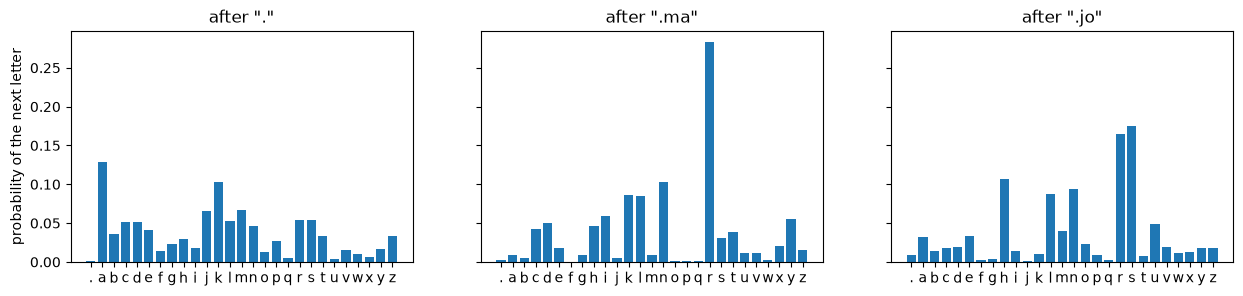

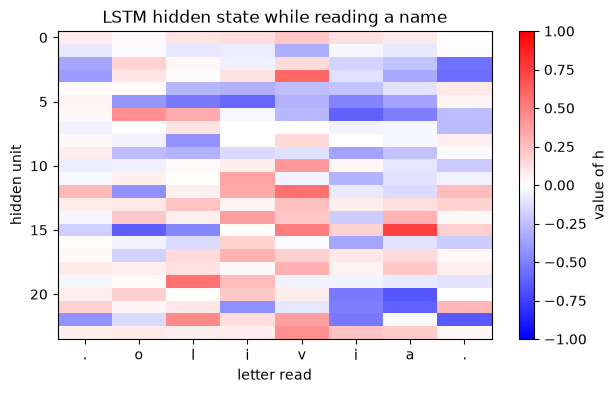

In [27]:
def next_letter_probs(model, prefix):
    with torch.no_grad():
        logits, _ = model(torch.tensor([[stoi[ch] for ch in prefix]]))
    return F.softmax(logits[0, -1], dim=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for ax, prefix in zip(axes, [".", ".ma", ".jo"]):
    ax.bar(list(chars), next_letter_probs(models["lstm"], prefix))
    ax.set_title(f'after "{prefix}"')
axes[0].set_ylabel("probability of the next letter"); plt.show()

name = ".olivia."
with torch.no_grad():
    states, _ = models["lstm"].rnn(F.one_hot(torch.tensor([[stoi[ch] for ch in name]]), V).float())
plt.figure(figsize=(7, 4))
plt.imshow(states[0, :, :24].T, cmap="bwr", vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(len(name)), list(name)); plt.xlabel("letter read"); plt.ylabel("hidden unit")
plt.colorbar(label="value of h"); plt.title("LSTM hidden state while reading a name"); plt.show()

**Questions 3.**
1. Before training, the loss was about 3.30. Show that this equals $\ln 27$ and explain why an untrained model gets exactly this value.
2. Compare the RNN and the LSTM: final validation loss and the generated names. Which is better, and is the difference large here? (Names are short — think about Task 2.)
3. In 3e, the probabilities after `.ma` and `.jo` are very different, but the model's input at that moment is a single letter (`a` or `o`). Where does the difference come from?
4. The model only ever predicts **one** next letter. How does `generate` turn that into a whole name? Why do we **sample** instead of always taking the most likely letter?

**Your answer:**

 - 1 Why the loss starts at about 3.30

 An untrained model has random small weights, so its 27 scores are almost equal. After softmax, every letter gets about the same probability: 1/27.

Cross-entropy loss is −ln(probability of the correct letter):

$$-\ln\left(\tfrac{1}{27}\right) = \ln 27 = 3.296$$

Our results were 3.299 (RNN) and 3.293 (LSTM), which is very close. The model knows nothing yet, so it spreads the probability evenly, and the loss is the same whatever the correct letter is.

- 2 RNN vs LSTM

before	after 5 epochs
RNN	3.299	2.182
LSTM	3.293	2.098

The LSTM is better, but the difference is small (about 0.08). Both models produce names that look realistic.

The reason the gap is small: names are short, usually 4–8 letters. To predict the next letter, the model mostly needs the last few letters. From Task 2, a plain RNN only loses memory over long distances (20, 50, 100 steps). Over 5 steps its gradient is still fine. The LSTM’s advantage would be much bigger on long sequences, like sentences or paragraphs.

(Add 2–3 of your generated names from each model here as examples.)

- 3 Why .ma and .jo give different predictions

The input at that step is only one letter, but the model also gets the hidden state (its memory). The hidden state was built from all the earlier letters: . → m → a in one case, and . → j → o in the other. So the two hidden states are different, and the predictions are different too.

This is the whole point of an RNN: the current input plus the memory of everything before it.

- 4 How generate builds a whole name

It runs a loop:

Start with . and an empty memory
The model predicts probabilities for the next letter
Pick one letter
Feed that letter back in as the next input, and keep the memory
Repeat until the model picks . (end of name), or 20 letters are reached

So one-letter-at-a-time predictions become a full name.

**Optional (not required).** *Temperature* controls how adventurous the generator is: divide the logits by a number $\tau$ before the softmax. Generate 15 names with $\tau = 0.5$ and $\tau = 1.5$ and describe the difference.

In [ ]:
# Optional: your code here

## Submission checklist
- [ ] Every `# TODO` filled, every `assert` passes, **Kernel → Restart & Run All** works
- [ ] All **Your answer** cells written (Questions 1, 2, 3)
- [ ] Hand calculations for 1a, 1c, 2a, 2b, and 3a done on paper first
- [ ] Tasks 1–2 done without AI; references listed
- [ ] Task 3 AI use recorded (tool + what for), or "no AI used"

**References / AI use:**

used only in task 3 where we had to move to the left one step, it was confusing cuz of slicing